First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Species names: ['setosa' 'versicolor' 'virginica']

K = 3
Accuracy: 0.9333

K = 5
Accuracy: 0.9333

K = 7
Accuracy: 0.9667

Best K: 7
Best Accuracy: 0.9667


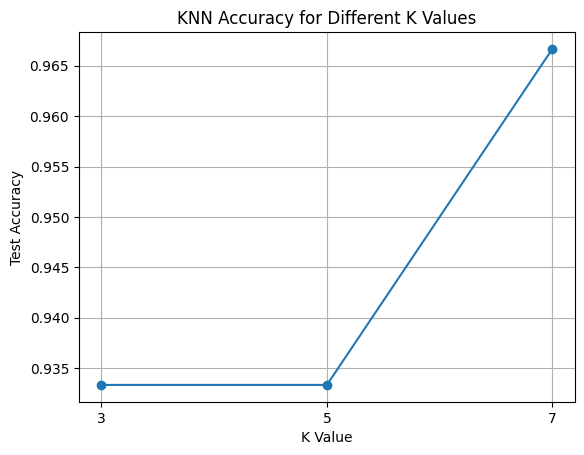

In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

print("First five rows:")
print(X.head())

print("\nSpecies names:", iris.target_names)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

k_values = [3, 5, 7]
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    accuracies.append(accuracy)

    print("\nK =", k)
    print("Accuracy:", round(accuracy, 4))

best_index = accuracies.index(max(accuracies))
best_k = k_values[best_index]

print("\nBest K:", best_k)
print("Best Accuracy:", round(accuracies[best_index], 4))

plt.plot(k_values, accuracies, marker="o")
plt.xlabel("K Value")
plt.ylabel("Test Accuracy")
plt.title("KNN Accuracy for Different K Values")
plt.xticks(k_values)
plt.grid(True)
plt.show()
